In [ ]:
from dataclasses import dataclass

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.utils.io import load_localizations
from IPython.display import display, SVG
from matplotlib.transforms import Bbox


COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}

In [ ]:
def angles_from_point(target_point, origin=(0.0, 0.0, 0.0)):
    """Return the selected vector and its spherical angles in original units.

    theta = atan2(dy, dx), wrapped to [0, 360) degrees.
    phi = atan2(hypot(dx, dy), dz), in [0, 180] degrees from +Z.
    Theta is None for a vector parallel to Z, since its azimuth is undefined.
    A target equal to the origin has no direction and raises ValueError.
    This standalone helper defaults to (0, 0, 0); compose_schematic_3d defaults
    to the box's minimum corner and passes that resolved origin explicitly.
    """
    target = np.asarray(target_point, dtype=float)
    origin = np.asarray(origin, dtype=float)
    if (
        target.shape != (3,)
        or origin.shape != (3,)
        or not np.all(np.isfinite(target))
        or not np.all(np.isfinite(origin))
    ):
        raise ValueError("target_point and origin must be finite XYZ triples.")
    vector = target - origin
    if not np.all(np.isfinite(vector)):
        raise ValueError(
            "The difference between target_point and origin must be finite."
        )
    rho = float(np.hypot(vector[0], vector[1]))
    length = float(np.hypot(rho, vector[2]))
    if length == 0:
        raise ValueError("target_point must differ from origin to define a direction.")
    if not np.isfinite(length):
        raise ValueError("The vector length must be finite.")
    theta = (
        None if rho == 0 else float(np.degrees(np.arctan2(vector[1], vector[0])) % 360)
    )
    phi = float(np.degrees(np.arctan2(rho, vector[2])))
    foot = target.copy()
    foot[2] = origin[2]
    return dict(
        origin=origin.copy(),
        target_point=target.copy(),
        vector=vector,
        xy_projection_point=foot,
        length=length,
        xy_length=rho,
        theta_deg=theta,
        phi_deg=phi,
    )


@dataclass(frozen=True)
class Rendered3D:
    image: np.ndarray
    bounds: tuple
    world_to_clip: np.ndarray
    camera_position: tuple

    def project(self, xyz):
        """World XYZ -> original screenshot pixels, with Y increasing upward."""
        xyz = np.asarray(xyz, dtype=float)
        xyz = np.atleast_2d(xyz)
        homogeneous = np.column_stack((xyz, np.ones(len(xyz))))
        clip = homogeneous @ self.world_to_clip.T
        if np.any(clip[:, 3] <= 0):
            raise ValueError("An annotation point lies behind the camera.")
        ndc = clip[:, :2] / clip[:, 3, None]
        h, w = self.image.shape[:2]
        return (ndc + 1) * np.array([w, h]) / 2


def render_schematic_3d(
    points,
    *,
    colors=None,
    window_size=(1400, 1400),
    point_size=5,
    opacity=0.2,
    azimuth=200,
    zoom=0.9,
    grid_color="#999999",
    camera_position=None,
):
    """Render the original 3D cloud and rear grid, without numeric labels.

    The default camera starts at PyVista's isometric view, then applies the
    supplied azimuth and zoom, matching the original code's intended view.
    A supplied camera_position=(position, focal_point, view_up) overrides that
    setup (azimuth/zoom are then ignored). Perspective remains enabled.
    Increase window_size for source raster detail. A camera override can be
    copied from p.camera_position in the original plot for an exact viewpoint.
    """
    import pyvista as pv

    colors = {"desmin": "#FF0000", "actinin": "#00FF00"} if colors is None else colors
    arrays = {}
    for name in ("desmin", "actinin"):
        a = np.asarray(points[name], dtype=float)
        if a.ndim != 2 or a.shape[1] != 3 or len(a) == 0 or not np.all(np.isfinite(a)):
            raise ValueError(f"{name} must contain finite N-by-3 coordinates.")
        arrays[name] = a
    if zoom <= 0:
        raise ValueError("zoom must be positive.")
    p = pv.Plotter(off_screen=True, window_size=window_size)
    try:
        for name, a in arrays.items():
            p.add_mesh(
                pv.PolyData(a.copy()),
                color=colors[name],
                style="points_gaussian",
                point_size=point_size,
                opacity=opacity,
            )
        bounds = tuple(p.bounds)
        p.set_background("black")
        axis = p.show_bounds(
            bounds=bounds,
            color=grid_color,
            grid="back",
            bold=False,
            font_size=20,
            font_family="arial",
            padding=0.0,
            use_3d_text=False,
            xtitle="",
            ytitle="",
            ztitle="",
        )
        axis.x_axis_label_visibility = False
        axis.y_axis_label_visibility = False
        axis.z_axis_label_visibility = False
        p.disable_parallel_projection()
        if camera_position is None:
            p.view_isometric()
            p.camera.azimuth = azimuth
            p.camera.zoom(zoom)
        else:
            p.camera_position = camera_position
        p.reset_camera_clipping_range()
        image = np.array(p.screenshot(transparent_background=False), copy=True)
        m = p.camera.GetCompositeProjectionTransformMatrix(
            p.renderer.GetTiledAspectRatio(),
            -1,
            1,
        )
        matrix = np.array([[m.GetElement(i, j) for j in range(4)] for i in range(4)])
        cpos = tuple(tuple(v) for v in p.camera_position)
    finally:
        p.close()
    return Rendered3D(image, bounds, matrix, cpos)


def compose_schematic_3d(
    rendered,
    *,
    scene_width=4.0,
    top_margin=0.25,
    bottom_margin=0.25,
    side_margin=0.15,
    axis_label_size=14,
    angle_label_size=14,
    arrow_linewidth=0.65,
    arrow_head_size=12,
    axis_fractions=(1.04, 1.04, 1.04),
    axis_label_offsets=((0, -9), (-10, 0), (-10, 5)),
    show_angles=True,
    target_point=None,
    origin=None,
    target_marker_size=3.5,
    return_geometry=False,
    theta_label_offset=(8, -5),
    phi_label_offset=(7, 1),
    guide_linewidth=0.8,
    arc_linewidth=0.65,
    theta_radius_fraction=0.7,
    phi_radius_fraction=0.6,
    font_family="DejaVu Sans",
):
    """Add +X/+Y/+Z, +theta/+phi, and independently controlled black margins.

    scene_width is the width in inches of the trimmed PyVista image. Labels
    and side margins can increase the total figure width. Top/bottom/side
    margins are inches OUTSIDE the combined image and annotation bounds;
    changing them does not zoom, stretch, or move the 3D geometry internally.
    Font sizes, arrow sizes, line widths and label offsets are points.

    origin=None selects (xmin, ymin, zmin). Supply origin=(x0, y0, z0) to change
    the common origin of the coordinate arrows, vector and angle arcs.
    target_point must be an absolute XYZ coordinate in the SAME coordinate
    system and units as the CSVs. It can be any chosen point, not necessarily
    a localization. The vector is target_point - origin and is never shortened
    or rescaled to fit the box. theta_deg, phi_deg and ray_fraction from the
    earlier version are replaced by target_point and origin.

    Theta runs from +X towards +Y in the XY plane, in [0, 360) degrees. Phi
    runs from +Z towards the vector, in [0, 180] degrees. Theta is undefined
    for a Z-parallel vector: omit its arc, and return theta_deg=None. For a
    -Z vector, draw the 180-degree phi arc in the XZ plane by convention.
    Zero-angle arcs are omitted. An open circle marks the exact endpoint.

    axis_fractions gives positive arrow lengths as fractions of data spans.
    Arc radius fractions affect the annotation size, never the computed angles.
    With return_geometry=True return (fig, ax, geometry), including both angles,
    the vector, its length, origin, target point and XY projection point.
    Otherwise preserve the original (fig, ax) return. With show_angles=False,
    the angle construction is hidden; geometry is still computed if supplied.
    """
    if scene_width <= 0 or min(top_margin, bottom_margin, side_margin) < 0:
        raise ValueError("Use a positive scene_width and nonnegative margins.")
    bounds = np.asarray(rendered.bounds, dtype=float).reshape(3, 2)
    spans = np.diff(bounds, axis=1).ravel()
    origin = bounds[:, 0].copy() if origin is None else np.asarray(origin, dtype=float)
    if origin.shape != (3,) or not np.all(np.isfinite(origin)):
        raise ValueError("origin must be a finite XYZ triple.")
    if np.any(spans <= 0):
        raise ValueError("The 3D schematic needs nonzero X, Y and Z spans.")
    if show_angles and target_point is None:
        raise ValueError(
            "Set target_point=(x, y, z), or show_angles=False for axes only."
        )
    geometry = None if target_point is None else angles_from_point(target_point, origin)
    if min(theta_radius_fraction, phi_radius_fraction) <= 0 or target_marker_size < 0:
        raise ValueError(
            "Use positive arc radius fractions and a nonnegative marker size."
        )
    # Resolve the geometry before creating a figure. Points may be outside the
    # data box, but must remain in front of the camera to project meaningfully.
    if show_angles:
        rendered.project(
            [
                geometry["origin"],
                geometry["target_point"],
                geometry["xy_projection_point"],
            ]
        )
    image = rendered.image
    occupied = np.any(image[..., :3] != 0, axis=2)
    rows, cols = np.nonzero(occupied)
    if rows.size == 0:
        raise ValueError("The render is entirely black; check the data and camera.")
    r0, r1, c0, c1 = rows.min(), rows.max() + 1, cols.min(), cols.max() + 1
    h = image.shape[0]
    extent = (c0, c1, h - r1, h - r0)
    scale = scene_width / (c1 - c0)  # Inches per original screenshot pixel.
    artists = []
    with mpl.rc_context({"font.family": font_family}):
        fig = plt.figure(
            figsize=(scene_width, scale * (r1 - r0)), facecolor="black", layout="none"
        )
        ax = fig.add_axes([0, 0, 1, 1], facecolor="black")
        artists.append(
            ax.imshow(
                image[r0:r1, c0:c1],
                origin="upper",
                extent=extent,
                interpolation="none",
                aspect="equal",
                zorder=0,
            )
        )
        ax.set_xlim(extent[:2])
        ax.set_ylim(extent[2:])
        ax.set_autoscale_on(False)
        ax.set_axis_off()

        def line3d(xyz, **kwargs):
            xy = rendered.project(xyz)
            (line,) = ax.plot(xy[:, 0], xy[:, 1], clip_on=False, zorder=3, **kwargs)
            artists.append(line)

        def arrow3d(start, end, *, lw=arrow_linewidth, head=arrow_head_size):
            a, b = rendered.project([start, end])
            artist = ax.annotate(
                "",
                xy=b,
                xytext=a,
                annotation_clip=False,
                arrowprops=dict(
                    arrowstyle="->",
                    color="white",
                    lw=lw,
                    mutation_scale=head,
                    shrinkA=0,
                    shrinkB=0,
                ),
                zorder=4,
            )
            artists.append(artist)

        def label3d(text, xyz, offset, size):
            xy = rendered.project(xyz)[0]
            artist = ax.annotate(
                text,
                xy=xy,
                xytext=offset,
                textcoords="offset points",
                color="white",
                fontsize=size,
                ha="center",
                va="center",
                annotation_clip=False,
                zorder=5,
            )
            artists.append(artist)

        for i, label in enumerate(("+x", "+y", "+z")):
            end = origin.copy()
            end[i] += axis_fractions[i] * spans[i]
            arrow3d(origin, end)
            label3d(label, end, axis_label_offsets[i], axis_label_size)

        if show_angles:
            theta = (
                0.0
                if geometry["theta_deg"] is None
                else np.deg2rad(geometry["theta_deg"])
            )
            phi = np.deg2rad(geometry["phi_deg"])
            length, rho = geometry["length"], geometry["xy_length"]
            tip, foot = geometry["target_point"], geometry["xy_projection_point"]
            for segment in ([origin, tip], [origin, foot], [foot, tip]):
                if not np.array_equal(segment[0], segment[1]):
                    line3d(segment, color="white", ls="--", lw=guide_linewidth)
            if target_marker_size > 0:
                xy = rendered.project(tip)[0]
                (marker,) = ax.plot(
                    *xy,
                    marker="o",
                    ms=target_marker_size,
                    mfc="none",
                    mec="white",
                    mew=guide_linewidth,
                    linestyle="none",
                    clip_on=False,
                    zorder=5,
                )
                artists.append(marker)

            if rho > 0 and theta > 0:
                t = np.linspace(0, theta, 128)
                rt = theta_radius_fraction * rho
                theta_arc = origin + rt * np.column_stack(
                    (np.cos(t), np.sin(t), np.zeros_like(t))
                )
                line3d(theta_arc, color="white", lw=arc_linewidth)
                arrow3d(
                    theta_arc[-5],
                    theta_arc[-1],
                    lw=arc_linewidth,
                    head=arrow_head_size * 0.75,
                )
                label3d(
                    "+θ", theta_arc[len(t) // 2], theta_label_offset, angle_label_size
                )

            if phi > 0:
                f = np.linspace(0, phi, 128)
                rp = phi_radius_fraction * length
                phi_arc = origin + rp * np.column_stack(
                    (np.sin(f) * np.cos(theta), np.sin(f) * np.sin(theta), np.cos(f))
                )
                line3d(phi_arc, color="white", lw=arc_linewidth)
                arrow3d(
                    phi_arc[-5],
                    phi_arc[-1],
                    lw=arc_linewidth,
                    head=arrow_head_size * 0.75,
                )
                label3d("+φ", phi_arc[len(f) // 2], phi_label_offset, angle_label_size)

        # Measure the image and vector annotations at a fixed physical scale.
        # Expand the canvas to hold that content plus the requested margins.
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        boxes = [a.get_window_extent(renderer) for a in artists]
        content = Bbox.union(boxes).padded(fig.dpi / 72)  # One point for stroke edges.
        content = content.transformed(ax.transData.inverted())
        content_width, content_height = content.width * scale, content.height * scale
        fw = content_width + 2 * side_margin
        fh = content_height + top_margin + bottom_margin
        fig.set_size_inches(fw, fh, forward=False)
        ax.set_position(
            [
                side_margin / fw,
                bottom_margin / fh,
                content_width / fw,
                content_height / fh,
            ]
        )
        ax.set_xlim(content.x0, content.x1)
        ax.set_ylim(content.y0, content.y1)
    return (fig, ax, geometry) if return_geometry else (fig, ax)


def make_schematic_3d(
    desmin_csv,
    actinin_csv,
    *,
    columns=("x (um)", "y (um)", "z (um)"),
    colors=None,
    render_kwargs=None,
    **layout_kwargs,
):
    """Load CSVs, render, and compose; pass target_point in layout_kwargs.

    Returns (fig, ax), or (fig, ax, geometry) when return_geometry=True.
    """
    points = load_localizations(desmin_csv, actinin_csv, columns=columns)
    rendered = render_schematic_3d(points, colors=colors, **(render_kwargs or {}))
    return compose_schematic_3d(rendered, **layout_kwargs)

In [ ]:
points = load_localizations(
    "../../source_data/fig_2/",
    prefix="2b_",
)

rendered = render_schematic_3d(points, colors=COLOR_DICT)

# Choose a localization, or supply your own (x, y, z) tuple.
target_point = points["desmin"][1734]

# Rerun from here when changing the selected point.
fig, ax, geometry = compose_schematic_3d(
    rendered,
    target_point=target_point,
    origin=None,  # Defaults to (xmin, ymin, zmin)
    return_geometry=True,
    scene_width=4.0,
    top_margin=0.25,
    bottom_margin=0.15,
    target_marker_size=5.0,
    theta_radius_fraction=0.3,
    phi_radius_fraction=0.3,
    theta_label_offset=(12, 5),
    phi_label_offset=(3, 13),
    axis_label_offsets=((0, -12), (-13, 3), (-10, 5)),
)

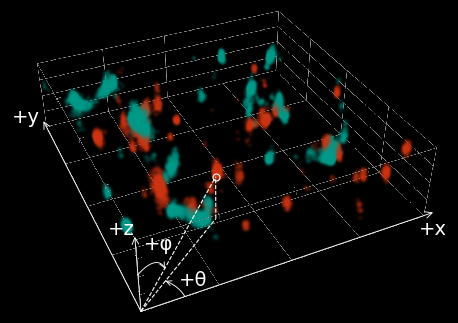

In [119]:
display(fig)

2026-09-27 21:19:08.620 (   0.689s) [    14C265B7C740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


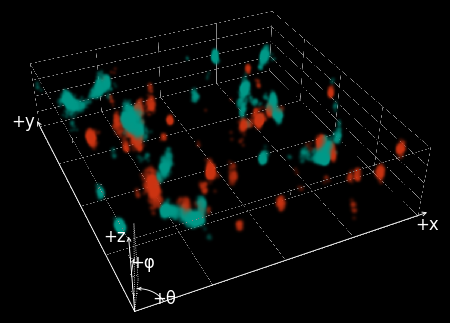

In [6]:
fig, ax = make_schematic_3d(
    "../../source_data/fig_2/",
    prefix="2b_",
    colors=COLOR_DICT,
    render_kwargs=dict(
        window_size=(1800, 1800),
        point_size=5,
        opacity=0.2,
        azimuth=200,
        zoom=0.9,
    ),
    scene_width=4.0,  # Rendered scene width, inches
    top_margin=0.25,  # Black margin above content, inches
    bottom_margin=0.15,  # Black margin below content, inches
    side_margin=0.15,
    axis_label_size=12,
    angle_label_size=12,
    arrow_linewidth=0.65,
    arrow_head_size=7,
    theta_deg=65,  # Illustrative angle in the XY plane
    phi_deg=30,  # Illustrative inclination from +Z
    theta_label_offset=(8, -5),  # Label offsets in points
    phi_label_offset=(7, 1),
)

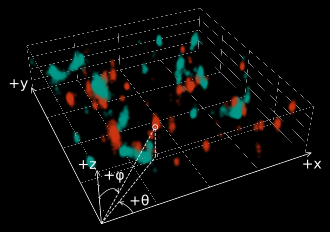

In [ ]:
savepath = "../../figures/2e"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)